### Continuar con segundo paso: proyectar estadisticos al menos hasta 2024

- Para una mejor comprension armar data frames para cada pais con todos los macroeconomicos de dicho pais **(hecho)**
    - para ello hacer merge de cada estadistico manteniendo todos los años en cada data frame y completando con NaN donde halla faltantes
- Luego de esto si hay pocos años los cuales deben completarse para llegar al 2024 buscarlos manualmente
    - luego de una busqueda no tan exhaustiva pero de fuentes confiables no se hallaron datos necesarios **(hecho)**
- De no encontrarse los estadisticos para estos datos o si la brecha de datos faltantes es demasiado grande: 
    - o utilizar buenas practicas de manejo de missing values (forward/backward/interpotaltion fill) ***APLICAR***
    - o utilizar regresores para predecir valores faltantes **Descartado: no modelaremos regresores por dos valres para 54 paises**

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import time
import os

In [2]:
australia_profile = pd.read_parquet("../data/by_country/Australia_macro_profile.parquet")
australia_profile.head()

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price
0,2007,NaN,NaN,NaN,NaN,NaN,NaN,78.7775,NaN,283.4875,NaN,NaN,NaN
1,2008,NaN,NaN,NaN,NaN,NaN,NaN,87.3575,NaN,309.1825,NaN,NaN,NaN
2,2009,NaN,NaN,NaN,NaN,NaN,NaN,86.2500,NaN,315.9400,NaN,NaN,NaN
3,2010,NaN,NaN,NaN,NaN,NaN,NaN,89.9575,NaN,341.5600,NaN,NaN,100.000
4,2011,NaN,NaN,NaN,NaN,NaN,NaN,97.0800,NaN,367.2525,NaN,NaN,97.845


In [3]:
australia_profile.tail()

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price
13,2020,13.58,90.6,46.25,86.24,113.1950,65.861667,111.7475,116.100,494.0275,2656.729167,6.441667,140.8525
14,2021,13.80,87.9,47.26,86.36,122.0550,68.871667,127.3975,119.425,550.6875,2760.232500,5.138333,165.3925
15,2022,14.07,87.5,47.26,86.49,133.1300,81.175833,142.0275,127.300,620.9125,2991.540000,3.725833,179.0200
16,2023,14.50,NaN,NaN,86.62,142.2425,90.190000,157.1425,134.425,655.5775,3173.511667,3.686667,178.6500
17,2024,NaN,NaN,NaN,NaN,154.9175,94.169167,166.4175,138.675,680.3275,3340.351667,3.686667,192.5275


In [7]:
import numpy as np

In [15]:
def plot_fill_methods_grid(df_country, macro_column, country_name):
    """
    Plots original and filled versions of a macroeconomic column using ffill, bfill, and interpolation
    in a 2x2 grid layout with integer year ticks and rotated labels.

    Parameters:
    - df_country: DataFrame with 'Year' and macroeconomic columns
    - macro_column: string name of the macroeconomic column to process
    """
    if macro_column not in df_country.columns:
        print(f"❌ Column '{macro_column}' not found in DataFrame.")
        return

    df_sorted = df_country.sort_values(by='Year').copy()
    df_sorted['Year'] = df_sorted['Year'].astype(int)

    years = df_sorted['Year']
    original = df_sorted[macro_column]
    ffill_series = original.ffill()
    bfill_series = original.bfill()
    interp_series = original.interpolate()

    fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

    axs[0, 0].plot(years, original, marker='o', linestyle='--', color='black')
    axs[0, 0].set_title('Original Data')

    axs[0, 1].plot(years, ffill_series, marker='x', linestyle='-', color='blue')
    axs[0, 1].set_title('Forward Fill (ffill)')

    axs[1, 0].plot(years, bfill_series, marker='^', linestyle='-', color='green')
    axs[1, 0].set_title('Backward Fill (bfill)')

    axs[1, 1].plot(years, interp_series, marker='s', linestyle='-', color='red')
    axs[1, 1].set_title('Interpolated')

    for ax in axs.flat:
        ax.set_xticks(np.arange(years.min(), years.max() + 1, 1))
        ax.set_xlabel("Year")
        ax.set_ylabel(macro_column)
        ax.grid(True)

    # Rotate x-axis labels for all subplots
    plt.setp(axs.flat, xticklabels=np.arange(years.min(), years.max() + 1, 1))
    for ax in axs.flat:
        for label in ax.get_xticklabels():
            label.set_rotation(45)

    plt.suptitle(f"Fill Method Comparison for '{macro_column}' in {country_name}", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


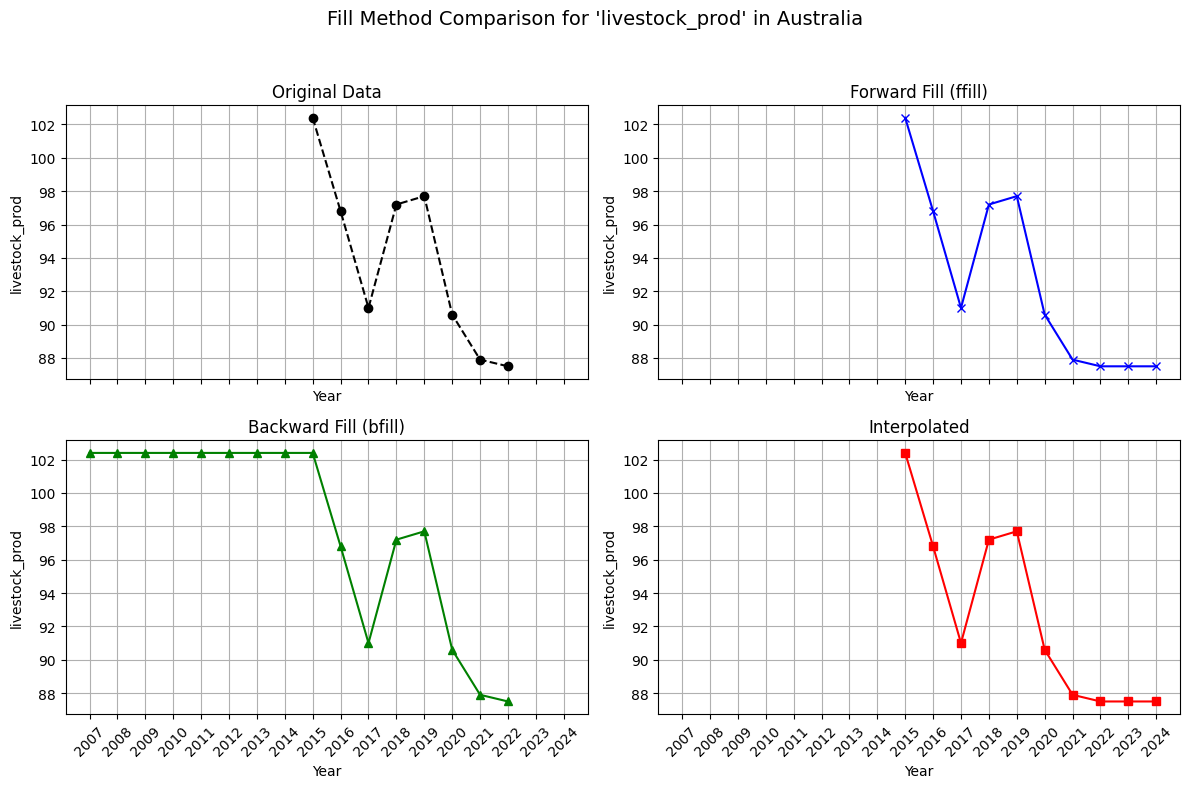

In [16]:
plot_fill_methods_grid(australia_profile, "livestock_prod", 'Australia')

**Observaciones:**
- podemos ver que la liena de tiempo corresponde para todos los años disponibles dentro del data frame del pais
- el line plot con los valores 'originales' o disponibles muestra que desde 2007 al 2015, este ultimo excluyente, no tenemos valores y luego del 2023 al 2024 tampoco
- se puede ver que el metodo bfill solo puede completar valores perdidos para años pasados, de alli su nombre backward fill
- vemos que el metodo de ffill y interpolate da como resultado el mismo relleno de valores, comprendemos que esto es lo esperado ya que la interpolacion normalemente se realiza entre dos valores y no para proyecciones

**Conclusion:** Utilizaremos ffill method ya que asumimos que mantener  mismos valores para rellenar los valores faltantes sera menos perjudicial que tratar de recrear una tendencia con tan pocos datos

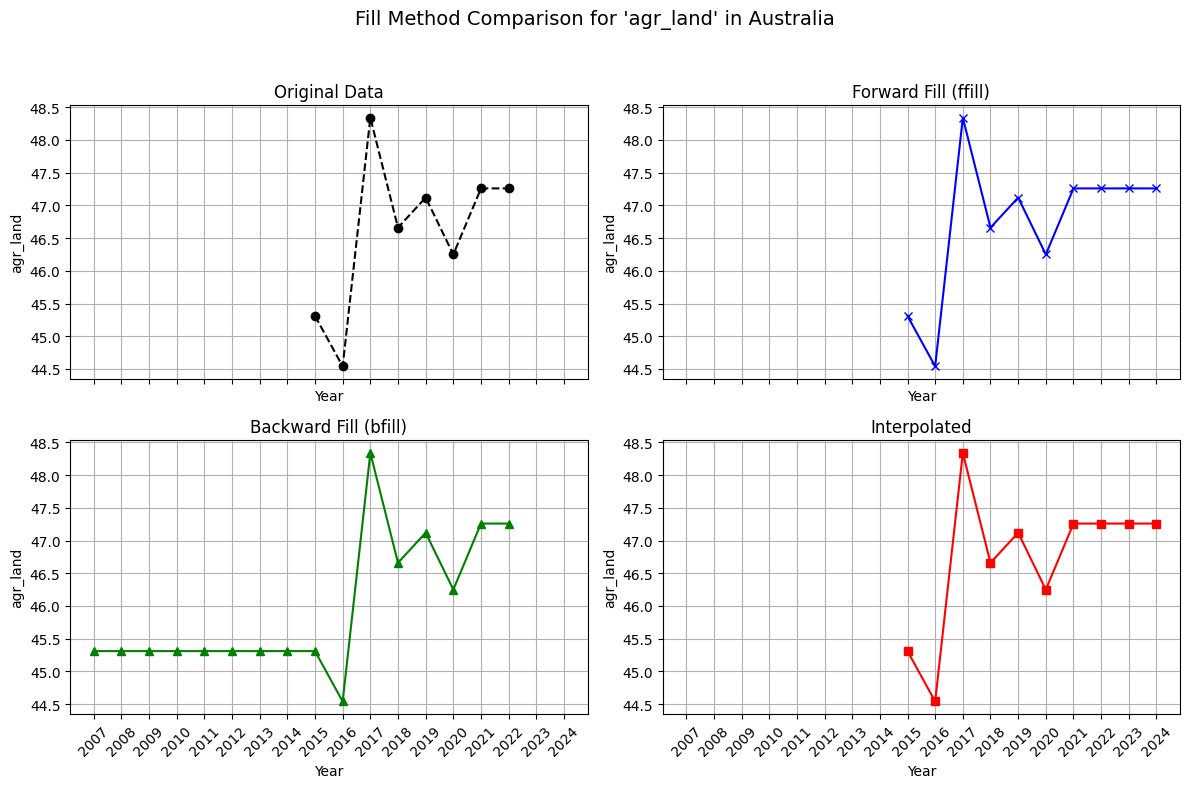

In [17]:
plot_fill_methods_grid(australia_profile, "agr_land", "Australia")

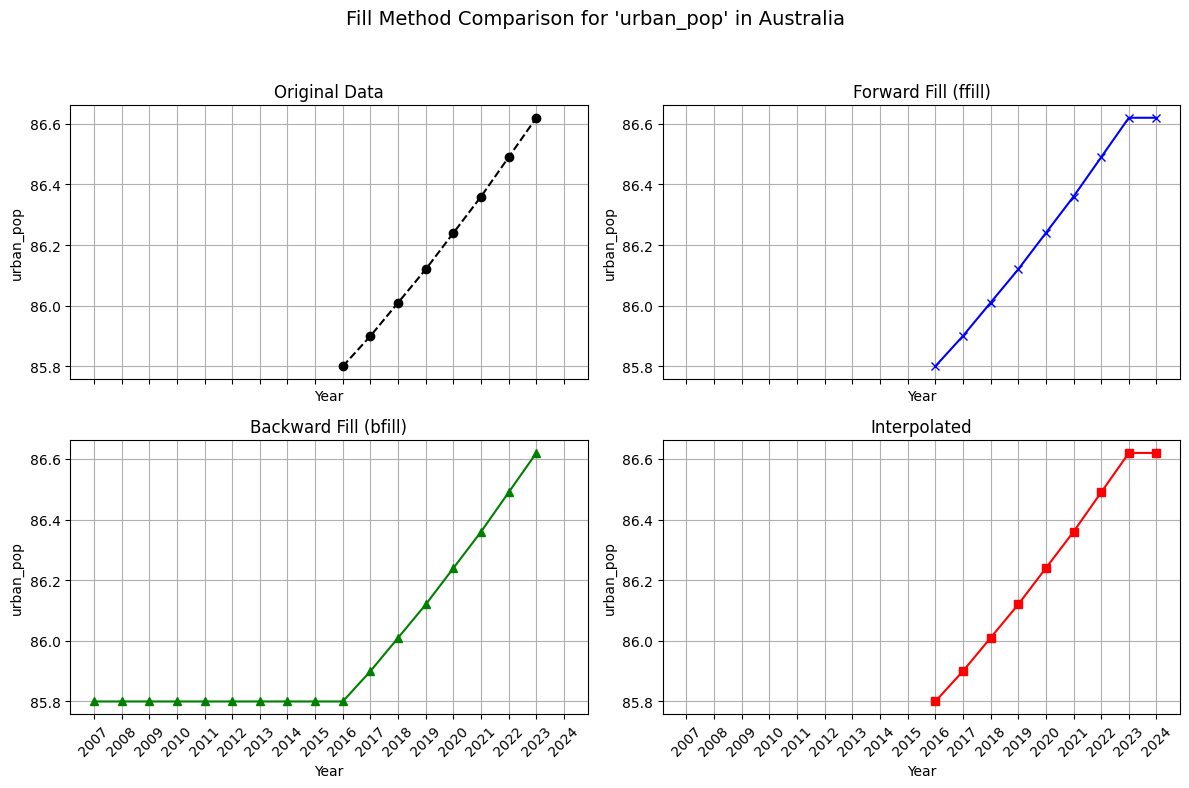

In [18]:
plot_fill_methods_grid(australia_profile, "urban_pop", "Australia")

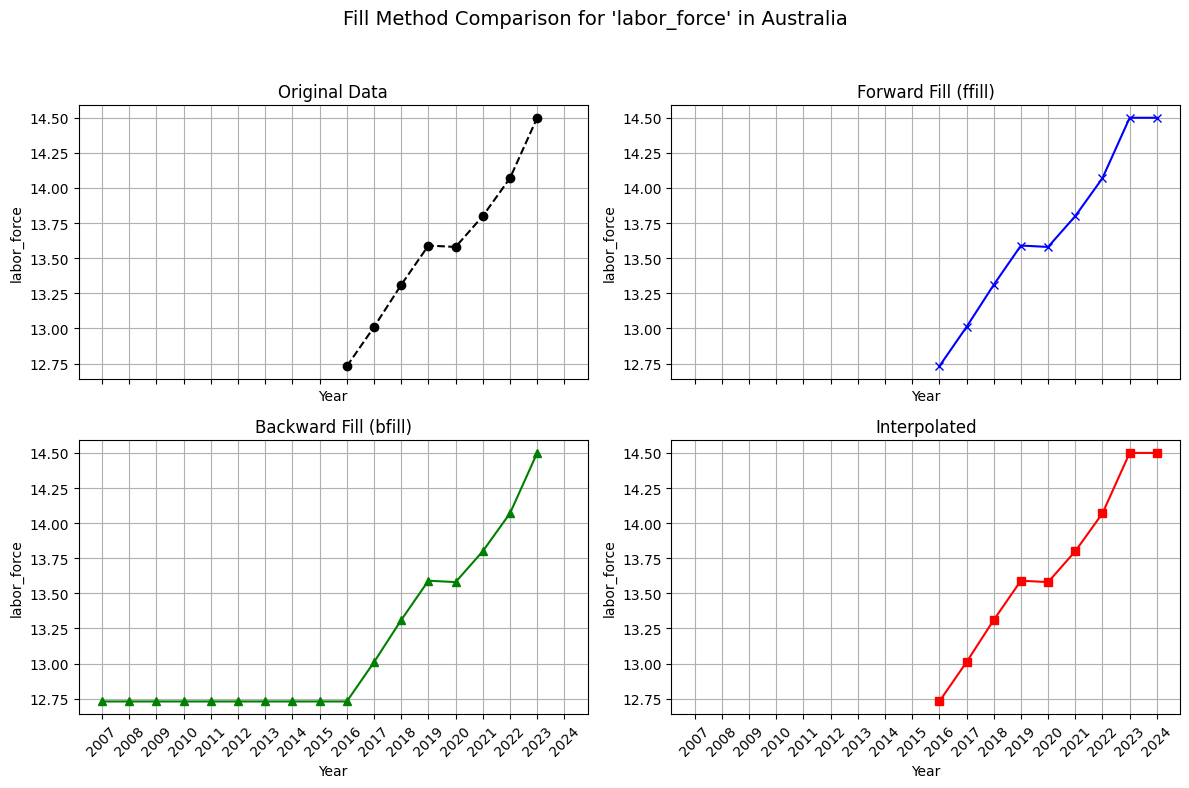

In [19]:
plot_fill_methods_grid(australia_profile, "labor_force", "Australia")

In [20]:
australia_profile.ffill()

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price
0,2007,NaN,NaN,NaN,NaN,NaN,NaN,78.7775,NaN,283.4875,NaN,NaN,NaN
1,2008,NaN,NaN,NaN,NaN,NaN,NaN,87.3575,NaN,309.1825,NaN,NaN,NaN
2,2009,NaN,NaN,NaN,NaN,NaN,NaN,86.2500,NaN,315.9400,NaN,NaN,NaN
3,2010,NaN,NaN,NaN,NaN,NaN,NaN,89.9575,NaN,341.5600,NaN,NaN,100.0000
4,2011,NaN,NaN,NaN,NaN,NaN,NaN,97.0800,NaN,367.2525,NaN,NaN,97.8450
5,2012,NaN,NaN,NaN,NaN,NaN,NaN,106.9800,101.025,378.9825,NaN,NaN,97.5325
6,2013,NaN,NaN,NaN,NaN,NaN,52.751667,106.8425,103.500,392.4275,NaN,NaN,103.9925
7,2014,NaN,NaN,NaN,NaN,NaN,60.172500,106.6775,106.075,403.4525,2059.295833,NaN,113.4075
8,2015,NaN,102.4,45.31,NaN,80.1975,62.596667,105.8950,107.675,409.8350,2207.458333,NaN,123.6450
9,2016,12.73,96.8,44.54,85.80,85.2900,60.568333,104.4575,109.050,424.6600,2367.798333,5.713333,130.4450


In [21]:
australia_profile = australia_profile.ffill()[(australia_profile['Year'] >= 2016)]
australia_profile

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price
9,2016,12.73,96.8,44.54,85.80,85.2900,60.568333,104.4575,109.050,424.6600,2367.798333,5.713333,130.4450
10,2017,13.01,91.0,48.34,85.90,89.7925,73.416667,109.4400,111.175,450.3775,2493.594167,5.606667,141.3350
11,2018,13.31,97.2,46.66,86.01,95.3525,71.986667,114.2550,113.300,473.9000,2550.039167,5.306667,139.3050
12,2019,13.59,97.7,47.12,86.12,103.7050,73.037500,113.9775,115.125,498.6975,2589.645000,5.165000,133.6400
13,2020,13.58,90.6,46.25,86.24,113.1950,65.861667,111.7475,116.100,494.0275,2656.729167,6.441667,140.8525
14,2021,13.80,87.9,47.26,86.36,122.0550,68.871667,127.3975,119.425,550.6875,2760.232500,5.138333,165.3925
15,2022,14.07,87.5,47.26,86.49,133.1300,81.175833,142.0275,127.300,620.9125,2991.540000,3.725833,179.0200
16,2023,14.50,87.5,47.26,86.62,142.2425,90.190000,157.1425,134.425,655.5775,3173.511667,3.686667,178.6500
17,2024,14.50,87.5,47.26,86.62,154.9175,94.169167,166.4175,138.675,680.3275,3340.351667,3.686667,192.5275


In [22]:
australia_profile = australia_profile.reset_index(drop=True)
australia_profile

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price
0,2016,12.73,96.8,44.54,85.80,85.2900,60.568333,104.4575,109.050,424.6600,2367.798333,5.713333,130.4450
1,2017,13.01,91.0,48.34,85.90,89.7925,73.416667,109.4400,111.175,450.3775,2493.594167,5.606667,141.3350
2,2018,13.31,97.2,46.66,86.01,95.3525,71.986667,114.2550,113.300,473.9000,2550.039167,5.306667,139.3050
3,2019,13.59,97.7,47.12,86.12,103.7050,73.037500,113.9775,115.125,498.6975,2589.645000,5.165000,133.6400
4,2020,13.58,90.6,46.25,86.24,113.1950,65.861667,111.7475,116.100,494.0275,2656.729167,6.441667,140.8525
5,2021,13.80,87.9,47.26,86.36,122.0550,68.871667,127.3975,119.425,550.6875,2760.232500,5.138333,165.3925
6,2022,14.07,87.5,47.26,86.49,133.1300,81.175833,142.0275,127.300,620.9125,2991.540000,3.725833,179.0200
7,2023,14.50,87.5,47.26,86.62,142.2425,90.190000,157.1425,134.425,655.5775,3173.511667,3.686667,178.6500
8,2024,14.50,87.5,47.26,86.62,154.9175,94.169167,166.4175,138.675,680.3275,3340.351667,3.686667,192.5275


In [25]:
def plot_macro_correlation_heatmap(df_country):
    """
    Plots a heatmap of the correlation matrix for macroeconomic indicators in a country DataFrame.

    Parameters:
    - df_country: DataFrame with 'Year' and macroeconomic columns
    """
    # Drop 'Year' column if present
    df_macro = df_country.drop(columns=['Year'], errors='ignore')

    # Compute correlation matrix
    corr_matrix = df_macro.corr()

    # Plot heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", square=True,
                cbar_kws={"shrink": 0.8}, linewidths=0.5, linecolor='gray')

    plt.title("Macroeconomic Correlation Heatmap", fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

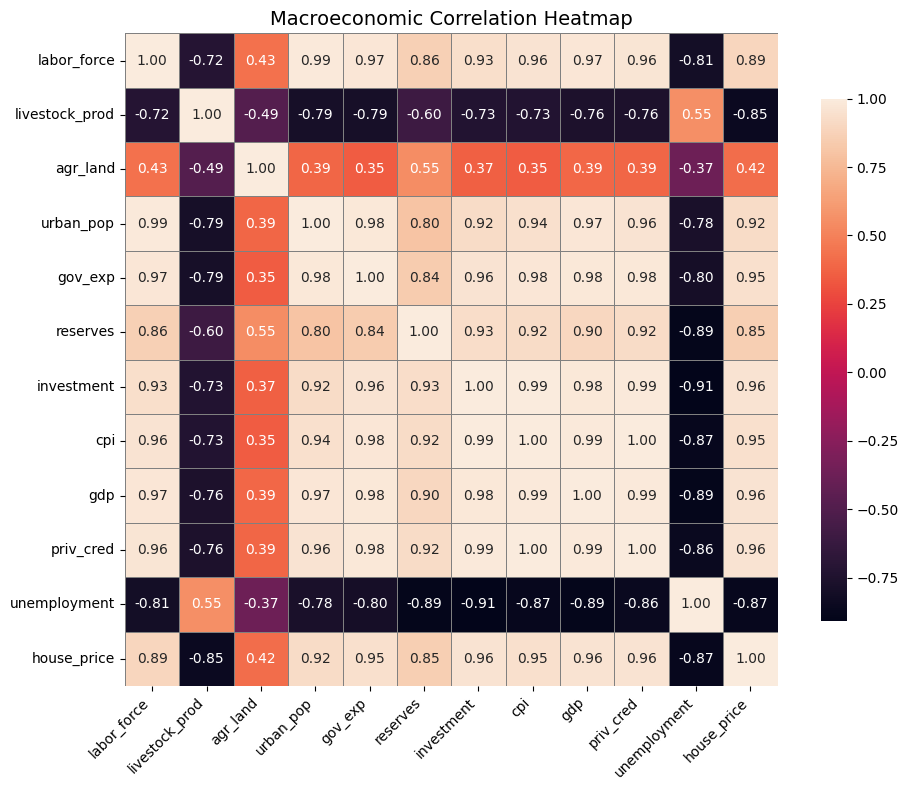

In [26]:
plot_macro_correlation_heatmap(australia_profile)

In [27]:
def correlation_ranking_with_partners(df_country, target_column='house_price', top_n=3):
    """
    Rank macroeconomic indicators by correlation with a target column (e.g., 'house_price').
    For each, list top and bottom correlated indicators.

    Parameters:
    - df_country: DataFrame with 'Year' and macroeconomic columns
    - target_column: column name to correlate against
    - top_n: number of strongest/weakest correlations to list for each indicator
    """
    # Drop 'Year' if present
    df_macro = df_country.drop(columns=['Year'], errors='ignore')

    if target_column not in df_macro.columns:
        print(f"❌ Target column '{target_column}' not found.")
        return None

    # Correlation matrix
    corr_matrix = df_macro.corr()

    # Sort indicators by absolute correlation with target_column
    target_corr = corr_matrix[target_column].drop(labels=[target_column])
    ranked_indicators = target_corr.abs().sort_values(ascending=False).index

    results = []

    for indicator in ranked_indicators:
        # Get correlations for the indicator, excluding itself
        corr_series = corr_matrix[indicator].drop(labels=[indicator])

        # Most correlated (excluding itself)
        most_corr = corr_series.sort_values(ascending=False).head(top_n)
        # Least correlated (most negative)
        least_corr = corr_series.sort_values(ascending=True).head(top_n)

        results.append({
            'Indicator': indicator,
            f'Corr_with_{target_column}': corr_matrix.loc[indicator, target_column],
            'Most_Correlated': list(most_corr.index),
            'Most_Correlated_Values': list(most_corr.values),
            'Least_Correlated': list(least_corr.index),
            'Least_Correlated_Values': list(least_corr.values)
        })

    return pd.DataFrame(results)

In [28]:
correlation_ranking_with_partners(australia_profile)

,Indicator,Corr_with_house_price,Most_Correlated,Most_Correlated_Values,Least_Correlated,Least_Correlated_Values
0,gdp,0.962743,"[priv_cred, cpi, gov_exp]","[0.9900223369118853, 0.988170949795592, 0.9837...","[unemployment, livestock_prod, agr_land]","[-0.8904929495772337, -0.7618029313072455, 0.3..."
1,investment,0.961909,"[cpi, priv_cred, gdp]","[0.9927026944141266, 0.9884082708453429, 0.983...","[unemployment, livestock_prod, agr_land]","[-0.9068844861596035, -0.7292444989776317, 0.3..."
2,priv_cred,0.956153,"[cpi, gdp, investment]","[0.9973483411020716, 0.9900223369118853, 0.988...","[unemployment, livestock_prod, agr_land]","[-0.8565736534403121, -0.7615430598421423, 0.3..."
3,cpi,0.947519,"[priv_cred, investment, gdp]","[0.9973483411020716, 0.9927026944141266, 0.988...","[unemployment, livestock_prod, agr_land]","[-0.8723352559209149, -0.734837259418242, 0.34..."
4,gov_exp,0.946663,"[urban_pop, priv_cred, gdp]","[0.9842165457878804, 0.9837954428339502, 0.983...","[unemployment, livestock_prod, agr_land]","[-0.798987265029333, -0.7914133738409854, 0.34..."
5,urban_pop,0.918298,"[labor_force, gov_exp, gdp]","[0.9868028000911203, 0.9842165457878804, 0.971...","[livestock_prod, unemployment, agr_land]","[-0.794782753073345, -0.7773976662480988, 0.38..."
6,labor_force,0.894961,"[urban_pop, gov_exp, gdp]","[0.9868028000911203, 0.9741360896688082, 0.973...","[unemployment, livestock_prod, agr_land]","[-0.8056921631377246, -0.7180314454633878, 0.4..."
7,unemployment,-0.870940,"[livestock_prod, agr_land, urban_pop]","[0.5543560547739638, -0.3743454909242386, -0.7...","[investment, gdp, reserves]","[-0.9068844861596035, -0.8904929495772337, -0...."
8,reserves,0.851226,"[investment, cpi, priv_cred]","[0.9312522317408205, 0.9223954424376011, 0.918...","[unemployment, livestock_prod, agr_land]","[-0.8880458169577687, -0.5968390164809905, 0.5..."
9,livestock_prod,-0.850175,"[unemployment, agr_land, reserves]","[0.5543560547739638, -0.48818232215708485, -0....","[house_price, urban_pop, gov_exp]","[-0.8501747741478685, -0.794782753073345, -0.7..."
